In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

ROOT = Path(r"F:\THESIS\mtech_thesis_crop_yield_estimation")
PROCESSED = ROOT / "data" / "processed"

# load SAR features and yield data
sar = pd.read_csv(PROCESSED / "sar_monthly_features.csv")
fields = gpd.read_file(PROCESSED / "yield_analysis_ready.gpkg")

print("SAR rows:", len(sar), "| yield rows:", len(fields))

# merge on uid (keep yield fields, attach SAR)
df = fields.merge(sar.drop(columns=["year"], errors="ignore"), on="uid", how="left")

# which SAR columns exist
sar_cols = [c for c in sar.columns if c.startswith(("VV_", "VH_", "ratio_"))]
print("SAR feature columns:", len(sar_cols))

# how many fields got SAR
has_sar = df[sar_cols].notna().all(axis=1)
print("fields with complete SAR:", int(has_sar.sum()), "of", len(df))
print("fields missing SAR:", int((~has_sar).sum()))

SAR rows: 1203 | yield rows: 1204
SAR feature columns: 18
fields with complete SAR: 1197 of 1204
fields missing SAR: 7


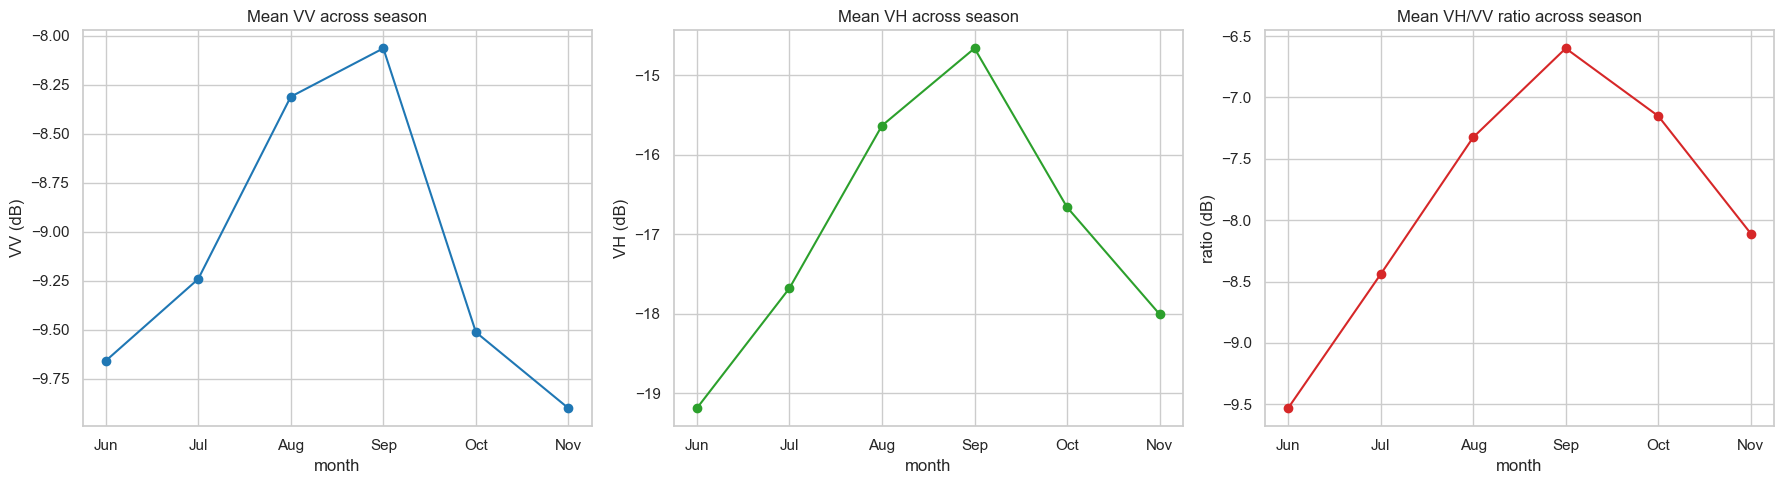

VV by month: [-9.66 -9.24 -8.31 -8.06 -9.51 -9.9 ]
VH by month: [-19.19 -17.68 -15.64 -14.66 -16.66 -18.01]
ratio by month: [-9.53 -8.44 -7.33 -6.6  -7.15 -8.11]


In [2]:
months = ["Jun", "Jul", "Aug", "Sep", "Oct", "Nov"]
vv_cols = [f"VV_{m}" for m in months]
vh_cols = [f"VH_{m}" for m in months]
ratio_cols = [f"ratio_{m}" for m in months]

# average across all fields per month
vv_mean = df[vv_cols].mean().values
vh_mean = df[vh_cols].mean().values
ratio_mean = df[ratio_cols].mean().values

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(months, vv_mean, "o-", color="tab:blue")
axes[0].set_title("Mean VV across season")
axes[0].set_ylabel("VV (dB)"); axes[0].set_xlabel("month")

axes[1].plot(months, vh_mean, "o-", color="tab:green")
axes[1].set_title("Mean VH across season")
axes[1].set_ylabel("VH (dB)"); axes[1].set_xlabel("month")

axes[2].plot(months, ratio_mean, "o-", color="tab:red")
axes[2].set_title("Mean VH/VV ratio across season")
axes[2].set_ylabel("ratio (dB)"); axes[2].set_xlabel("month")

plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "07_sar_season_curves.png", dpi=120)
plt.show()

print("VV by month:", np.round(vv_mean, 2))
print("VH by month:", np.round(vh_mean, 2))
print("ratio by month:", np.round(ratio_mean, 2))

## SAR seasonal curves (validation)

Mean VV, VH, and VH/VV ratio across the season (June to November), averaged over all 1197 fields with SAR data. This checks whether the extracted SAR actually captures crop growth.

All three curves show a clear inverted-V shape, rising from June, peaking in September, then falling toward November. This matches the soybean growth cycle:
- **June:** field just sown, bare soil or small plants, low backscatter.
- **July to August:** canopy builds, more plant structure scatters radar back, backscatter rises.
- **September:** full canopy and maximum biomass, peak backscatter.
- **October to November:** crop matures, dries and is harvested, backscatter drops back toward bare-soil levels.

**Why this validates the data.** A broken extraction (wrong fields, wrong dates, bad processing) would produce flat or random curves. Instead the curves trace a smooth, physically sensible phenology, confirming the right fields and season were sampled and the processing is correct. VH (cross-pol) shows the cleanest response (-19.2 dB in June to -14.7 dB in September), which is expected since VH is most sensitive to vegetation volume. The September peak represents maximum biomass, exactly the stage most likely to relate to final yield.

**Conclusion.** The SAR features are proper and capture real soybean phenology. This is the crop-condition signal absent from the field attributes, and the basis for expecting an improvement over the R2 = 0.07 baseline.

In [3]:
# only fields with complete SAR and a yield value
d = df[df[sar_cols].notna().all(axis=1) & df["crop_yield"].notna()].copy()
# exclude the flagged bad_geometry row etc. (use qc_flag if present)
if "qc_flag" in d.columns:
    d = d[d["qc_flag"] == ""]
print("fields used:", len(d))

# correlation of each SAR feature with yield
corr = d[sar_cols].corrwith(d["crop_yield"]).sort_values(key=abs, ascending=False)
print("\nSAR feature correlation with yield (strongest first):")
print(corr.round(3).to_string())

# organize by band and month for a clearer view
months = ["Jun", "Jul", "Aug", "Sep", "Oct", "Nov"]
summary = pd.DataFrame({
    "VV":    [d[f"VV_{m}"].corr(d["crop_yield"]) for m in months],
    "VH":    [d[f"VH_{m}"].corr(d["crop_yield"]) for m in months],
    "ratio": [d[f"ratio_{m}"].corr(d["crop_yield"]) for m in months],
}, index=months).round(3)
print("\ncorrelation with yield by month and band:")
print(summary.to_string())

fields used: 1197

SAR feature correlation with yield (strongest first):
VV_Jul       0.183
VH_Jul       0.144
VH_Nov      -0.129
VV_Aug       0.115
VH_Aug       0.113
ratio_Nov   -0.111
ratio_Jun   -0.084
VH_Sep      -0.068
VH_Jun      -0.063
ratio_Sep   -0.052
ratio_Oct    0.047
VV_Nov      -0.041
VV_Oct      -0.026
ratio_Jul   -0.022
VH_Oct       0.017
VV_Sep      -0.015
VV_Jun       0.009
ratio_Aug   -0.003

correlation with yield by month and band:
        VV     VH  ratio
Jun  0.009 -0.063 -0.084
Jul  0.183  0.144 -0.022
Aug  0.115  0.113 -0.003
Sep -0.015 -0.068 -0.052
Oct -0.026  0.017  0.047
Nov -0.041 -0.129 -0.111


fields per yield group:
yield_group
low       415
high      397
medium    385

yield range per group:
              min   max   mean
yield_group                   
low          1.00   7.5   6.05
medium       7.58   9.0   8.42
high         9.02  47.0  11.48


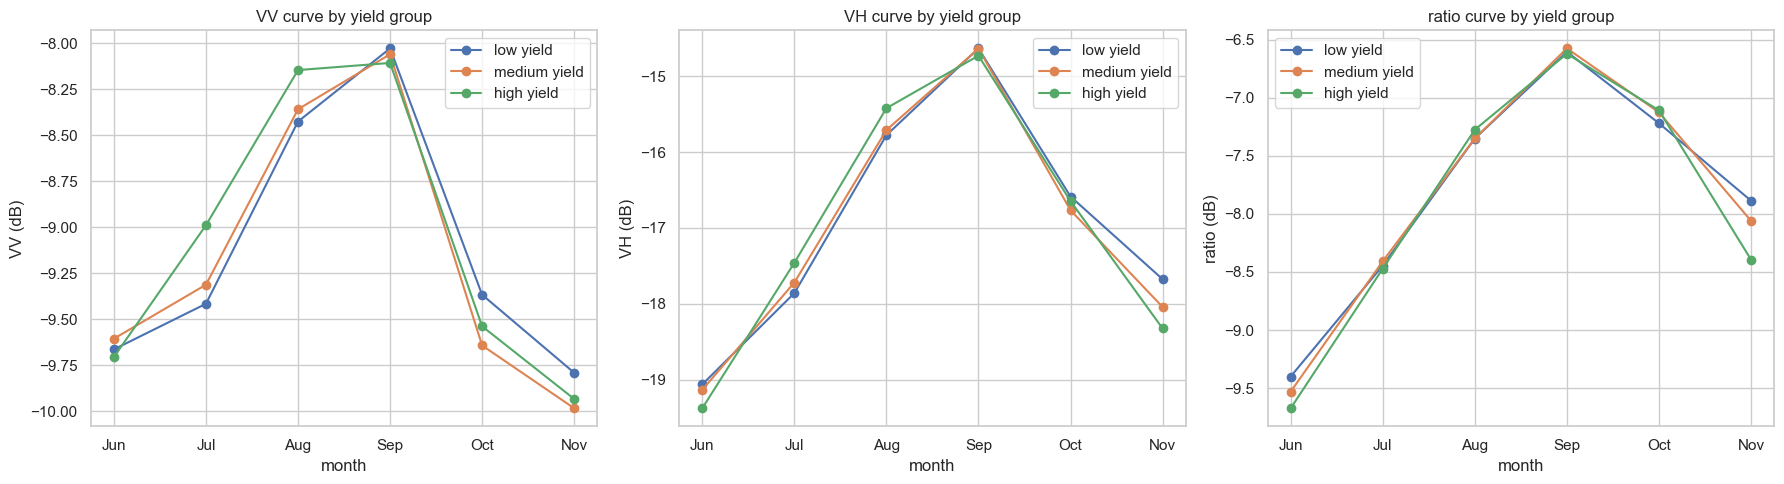

In [4]:
# split fields into yield tertiles (low / medium / high)
d = df[df[sar_cols].notna().all(axis=1) & df["crop_yield"].notna()].copy()
if "qc_flag" in d.columns:
    d = d[d["qc_flag"] == ""]

d["yield_group"] = pd.qcut(d["crop_yield"], 3, labels=["low", "medium", "high"])
print("fields per yield group:")
print(d["yield_group"].value_counts().to_string())
print("\nyield range per group:")
print(d.groupby("yield_group")["crop_yield"].agg(["min", "max", "mean"]).round(2).to_string())

months = ["Jun", "Jul", "Aug", "Sep", "Oct", "Nov"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for band, ax in zip(["VV", "VH", "ratio"], axes):
    cols = [f"{band}_{m}" for m in months]
    for grp in ["low", "medium", "high"]:
        curve = d[d["yield_group"] == grp][cols].mean().values
        ax.plot(months, curve, "o-", label=f"{grp} yield")
    ax.set_title(f"{band} curve by yield group")
    ax.set_xlabel("month"); ax.set_ylabel(f"{band} (dB)")
    ax.legend()

plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "08_sar_curves_by_yield.png", dpi=120)
plt.show()